# Chapitre 3 - Cours 6 : event sourcing, CQRS et DataFrames

Dans tous les modèles vus jusqu'ici, on lit les données **sous la forme où on les a
écrites** : documents, lignes, sommets et arêtes. Ce dernier cours présente deux modèles
qui rompent avec cette symétrie. L'**event sourcing** écrit un journal d'événements
immuables et en dérive des vues optimisées pour la lecture (**CQRS**) ; les
**DataFrames** et les **matrices** servent l'analyse de données et l'apprentissage
automatique. Il couvre les sections *Event Sourcing and CQRS* et *DataFrames, Matrices,
and Arrays*, ainsi que la fin du résumé du chapitre.

**Plan.**

1. Écrire des événements, lire des vues.
2. Commandes, événements et projections en code.
3. Rejouer le journal : reconstruire, corriger, ajouter une vue.
4. Les pièges de l'event sourcing.
5. DataFrames, matrices et tableaux.

In [1]:
import hashlib
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels_ed2 as e2
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Écrire des événements, lire des vues (section *Event Sourcing and CQRS*)

**Le problème.** Dans une application complexe, il est parfois impossible de trouver
**une** représentation des données qui serve bien toutes les façons de les lire et de
les afficher. Prenons l'exemple du livre, un système de gestion de conférence : des
participants s'inscrivent et paient par carte, des entreprises achètent des places par
lots sur facture puis les attribuent, des places sont réservées aux orateurs et aux
sponsors, des réservations sont annulées, et l'organisateur change de salle (donc de
capacité). Calculer simplement le **nombre de places disponibles** devient une requête
délicate.

**L'idée.** Puisqu'on dérive de toute façon des représentations à partir d'autres
(l'ETL, les vues matérialisées...), choisissons deux représentations distinctes :

- pour l'**écriture**, la plus simple et la plus expressive possible : un **journal
  d'événements**. Chaque changement est encodé comme un enregistrement autonome
  (horodaté) **ajouté** à la fin d'une séquence. Les événements sont **immuables** : on ne
  les modifie ni ne les supprime jamais, on en ajoute d'autres qui les remplacent ;
- pour la **lecture**, autant de **vues matérialisées** (aussi appelées *projections* ou
  *modèles de lecture*) que nécessaire, chacune mise à jour à chaque nouvel événement.

Utiliser les événements comme **source de vérité** s'appelle l'**event sourcing** ;
maintenir des représentations séparées optimisées pour la lecture, dérivées de la
représentation optimisée pour l'écriture, s'appelle **CQRS** (*command query
responsibility segregation*). Ces termes viennent de la communauté DDD
(*domain-driven design*), mais l'idée est ancienne : la réplication de machine à états
(chapitre 10) repose sur le même principe.

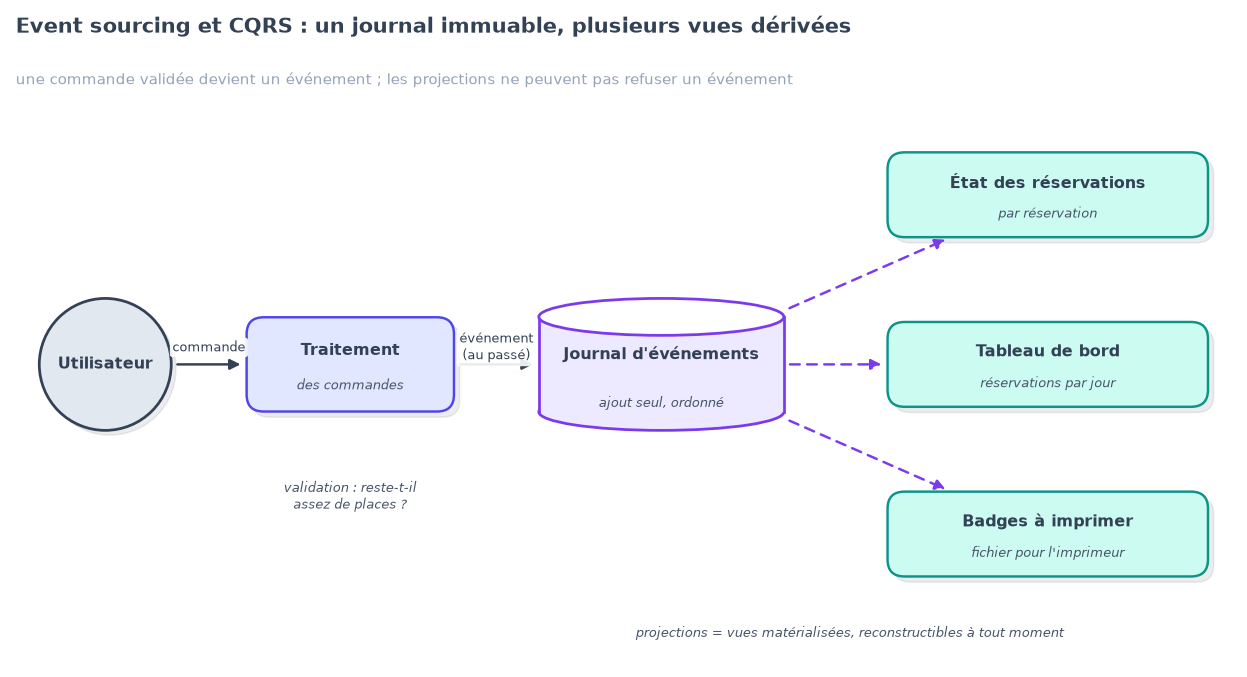

In [2]:
d = Diagram(13, 6.0, title="Event sourcing et CQRS : un journal immuable, plusieurs vues dérivées",
            subtitle="une commande validée devient un événement ; les projections ne peuvent pas refuser un événement")
d.box("u", 1.0, 3.2, "Utilisateur", kind="user", w=1.4, color=SLATE)
d.box("cmd", 3.6, 3.2, "Traitement", sub="des commandes", color=INDIGO, w=2.2, h=1.0)
d.box("log", 6.9, 3.2, "Journal d'événements", sub="ajout seul, ordonné", color=VIOLET, kind="db", w=2.6, h=1.4)
d.box("v1", 11.0, 5.0, "État des réservations", sub="par réservation", color=TEAL, w=3.4)
d.box("v2", 11.0, 3.2, "Tableau de bord", sub="réservations par jour", color=TEAL, w=3.4)
d.box("v3", 11.0, 1.4, "Badges à imprimer", sub="fichier pour l'imprimeur", color=TEAL, w=3.4)
d.arrow("u", "cmd", "commande")
d.arrow("cmd", "log", "événement\n(au passé)")
for v in ["v1", "v2", "v3"]:
    d.arrow("log", v, color=VIOLET, style="dashed")
d.note(3.6, 1.8, "validation : reste-t-il\nassez de places ?", fontsize=8.5)
d.note(8.9, 0.35, "projections = vues matérialisées, reconstructibles à tout moment", fontsize=8.5)
d.show()

Le vocabulaire compte. Une requête d'un utilisateur est une **commande** ; elle doit
d'abord être **validée** (reste-t-il assez de places ?). Une fois exécutée et jugée
valide, elle devient un **fait**, et l'événement correspondant est ajouté au journal. Le
journal ne contient donc que des événements valides, et une projection **n'a pas le
droit** de refuser un événement. On nomme les événements **au passé** (« des places ont
été réservées ») : c'est le constat que quelque chose s'est produit. Si la personne annule
ensuite, il reste vrai qu'elle a réservé ; l'annulation est un **autre** événement.

> **À retenir.** Event sourcing : le journal d'événements immuables est la source de
> vérité. CQRS : des vues de lecture séparées en sont dérivées. Commande (à valider)
> puis événement (un fait au passé, que personne ne peut plus refuser).

## 2. Commandes, événements et projections en code

Le module `ddia.datamodels_ed2` implémente ce schéma : `ConferenceService` valide les
commandes et ajoute les événements à un `EventLog` ; quatre projections s'y abonnent
(`AvailableSeats`, `BookingStatus`, `DailyDashboard`, `BadgeList`). Simulons deux mois
d'inscriptions : 3 000 commandes, des réservations individuelles et par lots, 12 %
d'annulations, et un changement de salle à mi-parcours (capacité de 2 500 à 3 750).

In [3]:
svc = e2.ConferenceService()
statut = svc.log.subscribe(e2.BookingStatus())
dash = svc.log.subscribe(e2.DailyDashboard())
badges = svc.log.subscribe(e2.BadgeList())
cmds = e2.make_conference_commands(3000, capacity=2500, seed=1)
dispo = []
for ts, c in cmds:
    svc.handle(c, ts)
    dispo.append((ts, svc.state.available, svc.state.capacity))
ev = pd.DataFrame([{"seq": e.seq, "jour": e.ts / 86400, "type": e.type, **e.data} for e in svc.log.events])
print(f"{len(cmds)} commandes -> {len(svc.log.events)} événements ; {len(svc.rejected)} commandes refusées")
ev.head(6)

3001 commandes -> 2076 événements ; 925 commandes refusées


,seq,jour,type,capacity,booking,client,seats
0,0,0.000,RegistrationOpened,2500.0,NaN,NaN,NaN
1,1,0.047,SeatsBooked,NaN,R00000,participant 0,1.0
2,2,0.088,SeatsBooked,NaN,R00001,participant 1,1.0
3,3,0.165,SeatsBooked,NaN,R00002,participant 2,1.0
4,4,0.176,SeatsBooked,NaN,R00003,participant 3,1.0
5,5,0.206,SeatsBooked,NaN,R00004,participant 4,1.0


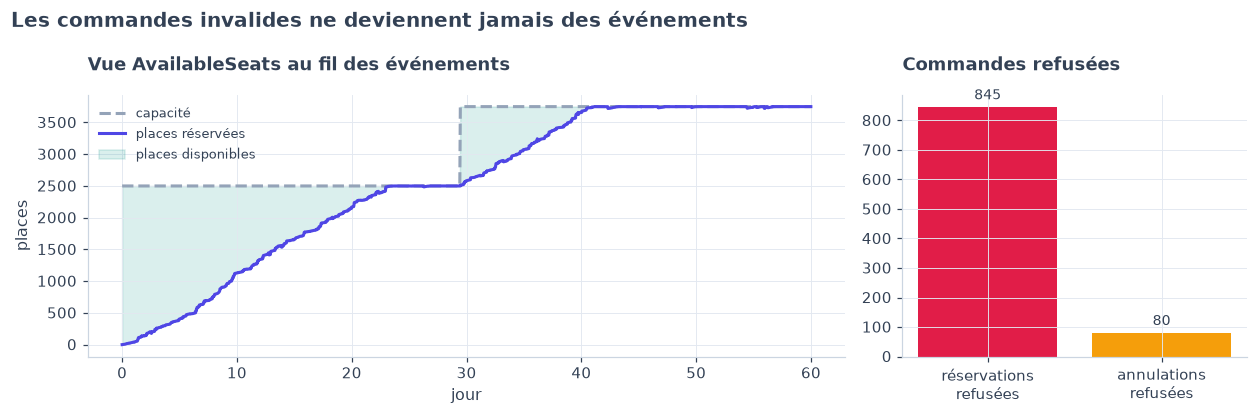

In [4]:
rej = pd.Series([c["cmd"] for _, c in svc.rejected]).value_counts()
dispo = pd.DataFrame(dispo, columns=["ts", "disponibles", "capacité"])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.plot(dispo.ts / 86400, dispo["capacité"], color=GRAY, ls="--", label="capacité")
ax.plot(dispo.ts / 86400, dispo["capacité"] - dispo["disponibles"], color=INDIGO, label="places réservées")
ax.fill_between(dispo.ts / 86400, dispo["capacité"] - dispo["disponibles"], dispo["capacité"], color=TEAL, alpha=0.15,
                label="places disponibles")
ax.set_xlabel("jour"); ax.set_ylabel("places"); ax.legend(fontsize=8.5)
ax.set_title("Vue AvailableSeats au fil des événements")
axes[1].bar(["réservations\nrefusées", "annulations\nrefusées"],
            [rej.get("book", 0), rej.get("cancel", 0)], color=[ROSE, AMBER])
annotate_bars(axes[1], "{:.0f}"); axes[1].set_title("Commandes refusées")
finish(fig, "Les commandes invalides ne deviennent jamais des événements")

Les réservations refusées sont celles qui arrivent quand la salle est pleine (avant le
changement de salle, puis à nouveau à la fin) ; les annulations refusées portent sur une
réservation déjà annulée. Aucune ne laisse de trace dans le journal. Chaque projection
présente les mêmes faits sous une forme différente :

In [5]:
print("état des réservations :", dict(list(statut.status.items())[:2]))
print("badges à imprimer     :", len(badges.badges), "dont", badges.badges[:3])
dash.frame().head()

état des réservations : {'R00000': {'client': 'participant 0', 'places': 1, 'etat': 'annulée'}, 'R00001': {'client': 'participant 1', 'places': 1, 'etat': 'confirmée'}}
badges à imprimer     : 3750 dont ['participant 1 #1', 'participant 2 #1', 'participant 3 #1']


,reservations,places,annulations
0,43,43,2
1,39,112,9
2,52,138,11
3,41,78,4
4,45,89,4


Les projections sont mises à jour **après** l'ajout de l'événement, souvent de façon
asynchrone par un autre processus. Un utilisateur qui lit une vue juste après sa
commande peut donc la trouver **en retard** : c'est le prix de la séparation écriture /
lecture, que nous retrouverons avec le retard de réplication (chapitre
6) et le traitement de flux (chapitre 12).

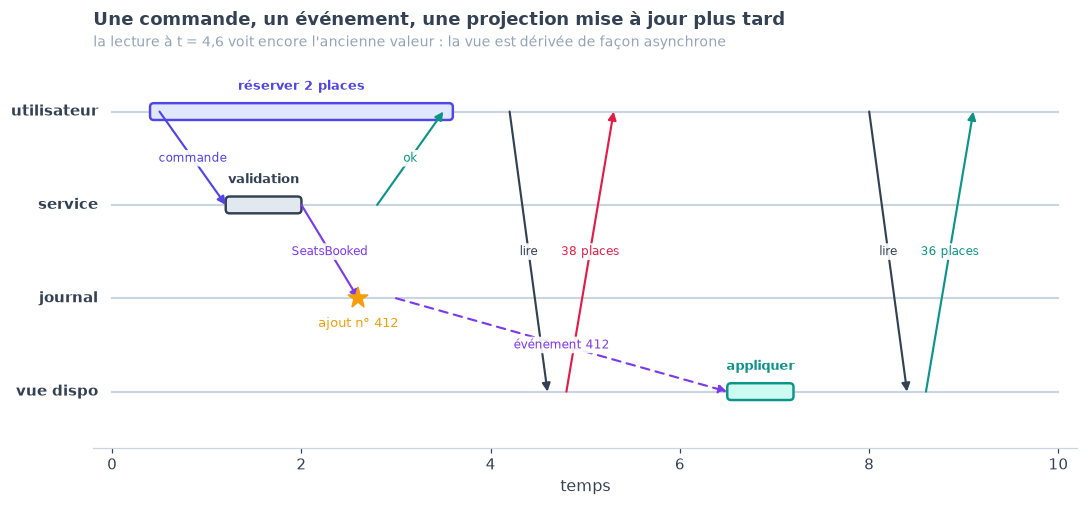

In [6]:
st = SpaceTime(["utilisateur", "service", "journal", "vue dispo"], t_max=10,
               title="Une commande, un événement, une projection mise à jour plus tard",
               subtitle="la lecture à t = 4,6 voit encore l'ancienne valeur : la vue est dérivée de façon asynchrone")
st.op("utilisateur", 0.4, 3.6, "réserver 2 places", color=INDIGO)
st.msg("utilisateur", 0.5, "service", 1.2, "commande", color=INDIGO)
st.op("service", 1.2, 2.0, "validation", color=SLATE)
st.msg("service", 2.0, "journal", 2.6, "SeatsBooked", color=VIOLET)
st.event("journal", 2.6, "ajout n° 412", kind="star")
st.msg("service", 2.8, "utilisateur", 3.5, "ok", color=TEAL)
st.msg("utilisateur", 4.2, "vue dispo", 4.6, "lire", color=SLATE)
st.msg("vue dispo", 4.8, "utilisateur", 5.3, "38 places", color=ROSE)
st.msg("journal", 3.0, "vue dispo", 6.5, "événement 412", color=VIOLET, style="dashed")
st.op("vue dispo", 6.5, 7.2, "appliquer", color=TEAL)
st.msg("utilisateur", 8.0, "vue dispo", 8.4, "lire", color=SLATE)
st.msg("vue dispo", 8.6, "utilisateur", 9.1, "36 places", color=TEAL)
st.show()

> **À retenir.** Le service valide les commandes et n'écrit que des faits ; chaque
> projection consomme les mêmes événements pour bâtir sa propre représentation. Une
> projection mise à jour de façon asynchrone peut être momentanément en retard.